# Exploration du jeu de données NSL-KDD

Avant de construire un modèle, on regarde les données de près. Ce notebook cherche à répondre à cinq questions :

1. Comment les classes sont-elles réparties, et en quoi l'entraînement diffère-t-il du test ?
2. Quels types d'attaques n'apparaissent que dans le test ?
3. Les données sont-elles propres (valeurs manquantes, doublons, colonnes inutiles) ?
4. Que contiennent les variables catégorielles, et y a-t-il des valeurs inconnues à l'entraînement ?
5. Quelles variables numériques distinguent le mieux le trafic normal des attaques ?

La colonne `difficulty` fournie avec les fichiers n'est jamais utilisée : elle est calculée à partir des résultats de classifieurs de référence, la prendre comme variable reviendrait à tricher.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from intrusion_detector.data import (
    CATEGORICAL_FEATURES,
    CATEGORIES,
    FEATURE_NAMES,
    NUMERIC_FEATURES,
    PROJECT_ROOT,
    load_test,
    load_train,
)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {
    "normal": "#2a9d8f",
    "dos": "#e76f51",
    "probe": "#e9c46a",
    "r2l": "#9b5de5",
    "u2r": "#264653",
}

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chargement et répartition des classes

In [2]:
train = load_train()
test = load_test()

print(f"Entraînement : {len(train):,} connexions".replace(",", " "))
print(f"Test         : {len(test):,} connexions".replace(",", " "))

train[["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "label", "category"]].head()

Entraînement : 125 973 connexions
Test         : 22 544 connexions


,duration,protocol_type,service,flag,src_bytes,dst_bytes,label,category
0,0,tcp,ftp_data,SF,491,0,normal,normal
1,0,udp,other,SF,146,0,normal,normal
2,0,tcp,private,S0,0,0,neptune,dos
3,0,tcp,http,SF,232,8153,normal,normal
4,0,tcp,http,SF,199,420,normal,normal


In [3]:
def class_table(df):
    counts = df["category"].value_counts().reindex(CATEGORIES)
    return pd.DataFrame({"connexions": counts, "part (%)": (counts / counts.sum() * 100).round(2)})


pd.concat({"entraînement": class_table(train), "test": class_table(test)}, axis=1)

entraînement                test         
           connexions part (%) connexions part (%)
category                                          
normal          67343    53.46       9711    43.08
dos             45927    36.46       7458    33.08
probe           11656     9.25       2421    10.74
r2l               995     0.79       2754    12.22
u2r                52     0.04        200     0.89

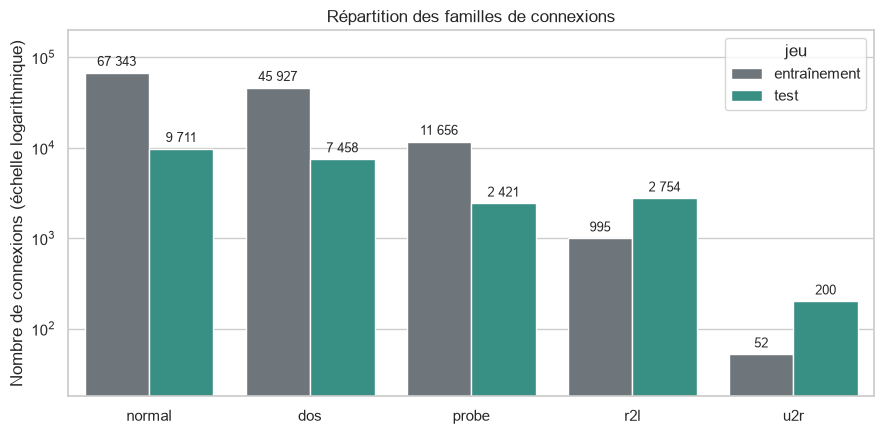

In [4]:
long = pd.concat(
    [
        train["category"].value_counts().reindex(CATEGORIES).rename("connexions").to_frame().assign(jeu="entraînement"),
        test["category"].value_counts().reindex(CATEGORIES).rename("connexions").to_frame().assign(jeu="test"),
    ]
).rename_axis("famille").reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=long, x="famille", y="connexions", hue="jeu", palette=["#6c757d", "#2a9d8f"], ax=ax)
ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("Nombre de connexions (échelle logarithmique)")
ax.set_title("Répartition des familles de connexions")
for container in ax.containers:
    ax.bar_label(container, fmt=lambda v: f"{int(v):,}".replace(",", " "), padding=3, fontsize=9)
ax.margins(y=0.15)
fig.tight_layout()
fig.savefig(FIG_DIR / "class_distribution.png", dpi=150)
plt.show()

In [5]:
for name, df in [("entraînement", train), ("test", test)]:
    attack_share = df["is_attack"].mean() * 100
    print(f"{name:12s} : {100 - attack_share:.1f} % normal, {attack_share:.1f} % attaques")

entraînement : 53.5 % normal, 46.5 % attaques
test         : 43.1 % normal, 56.9 % attaques


## 2. Les types d'attaques absents de l'entraînement

In [6]:
train_types = set(train["label"]) - {"normal"}
test_types = set(test["label"]) - {"normal"}
unseen = sorted(test_types - train_types)

print(f"Types d'attaque dans l'entraînement : {len(train_types)}")
print(f"Types d'attaque dans le test        : {len(test_types)}")
print(f"Types présents uniquement dans le test : {len(unseen)}")

unseen_mask = test["label"].isin(unseen)
print(f"\nConnexions de test concernées : {unseen_mask.sum():,} sur {test['is_attack'].sum():,} attaques "
      f"({unseen_mask.sum() / test['is_attack'].sum() * 100:.1f} %)".replace(",", " "))

Types d'attaque dans l'entraînement : 22
Types d'attaque dans le test        : 37
Types présents uniquement dans le test : 17

Connexions de test concernées : 3 750 sur 12 833 attaques (29.2 %)


In [7]:
unseen_table = (
    test[unseen_mask]
    .groupby(["label", "category"], observed=True)
    .size()
    .rename("connexions dans le test")
    .reset_index()
    .sort_values("connexions dans le test", ascending=False)
    .reset_index(drop=True)
)
unseen_table

,label,category,connexions dans le test
0,mscan,probe,996
1,apache2,dos,737
2,processtable,dos,685
3,snmpguess,r2l,331
4,saint,probe,319
5,mailbomb,dos,293
6,snmpgetattack,r2l,178
7,httptunnel,u2r,133
8,named,r2l,17
9,ps,u2r,15


In [8]:
share_unseen = (
    test[test["is_attack"] == 1]
    .assign(inconnue=unseen_mask)
    .groupby("category", observed=True)["inconnue"]
    .agg(["sum", "count", "mean"])
)
share_unseen.columns = ["connexions inconnues", "connexions test", "part inconnue"]
share_unseen["part inconnue"] = (share_unseen["part inconnue"] * 100).round(1)
share_unseen.rename(columns={"part inconnue": "part inconnue (%)"})

,connexions inconnues,connexions test,part inconnue (%)
category,,,
dos,1717,7458,23.0
probe,1315,2421,54.3
r2l,555,2754,20.2
u2r,163,200,81.5


## 3. Qualité des données

In [9]:
print("Valeurs manquantes (entraînement) :", int(train.isna().sum().sum()))
print("Valeurs manquantes (test)         :", int(test.isna().sum().sum()))
print("Doublons exacts (entraînement)    :", int(train[FEATURE_NAMES].duplicated().sum()))
print("Doublons exacts (test)            :", int(test[FEATURE_NAMES].duplicated().sum()))

constant = [c for c in NUMERIC_FEATURES if train[c].nunique() == 1]
print("\nColonnes constantes à l'entraînement :", constant)

Valeurs manquantes (entraînement) : 0
Valeurs manquantes (test)         : 0
Doublons exacts (entraînement)    : 16
Doublons exacts (test)            : 57

Colonnes constantes à l'entraînement : ['num_outbound_cmds']


## 4. Variables catégorielles

In [10]:
for col in CATEGORICAL_FEATURES:
    in_train, in_test = set(train[col]), set(test[col])
    print(f"{col:14s} {len(in_train):3d} valeurs à l'entraînement, {len(in_test):3d} dans le test, "
          f"absentes de l'entraînement : {sorted(in_test - in_train)}")

protocol_type    3 valeurs à l'entraînement,   3 dans le test, absentes de l'entraînement : []
service         70 valeurs à l'entraînement,  64 dans le test, absentes de l'entraînement : []
flag            11 valeurs à l'entraînement,  11 dans le test, absentes de l'entraînement : []


In [11]:
pd.crosstab(train["category"], train["protocol_type"], normalize="index").mul(100).round(1)

protocol_type,icmp,tcp,udp
category,,,
normal,1.9,79.6,18.5
dos,6.2,91.9,1.9
probe,35.5,50.2,14.3
r2l,0.0,100.0,0.0
u2r,0.0,94.2,5.8


## 5. Variables numériques

In [12]:
train[["duration", "src_bytes", "dst_bytes"]].describe().round(0).astype(int)

,duration,src_bytes,dst_bytes
count,125973,125973,125973
mean,287,45567,19779
std,2605,5870331,4021269
min,0,0,0
25%,0,0,0
50%,0,44,0
75%,0,276,516
max,42908,1379963888,1309937401


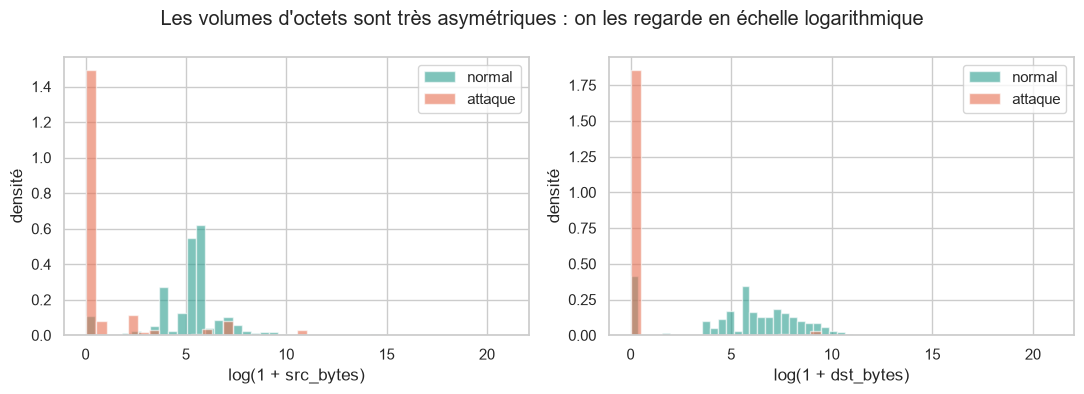

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["src_bytes", "dst_bytes"]):
    for group, color in [("normal", PALETTE["normal"]), ("attaque", "#e76f51")]:
        mask = train["is_attack"] == (0 if group == "normal" else 1)
        ax.hist(np.log1p(train.loc[mask, col]), bins=40, alpha=0.6, density=True, label=group, color=color)
    ax.set_xlabel(f"log(1 + {col})")
    ax.set_ylabel("densité")
    ax.legend()
fig.suptitle("Les volumes d'octets sont très asymétriques : on les regarde en échelle logarithmique")
fig.tight_layout()
plt.show()

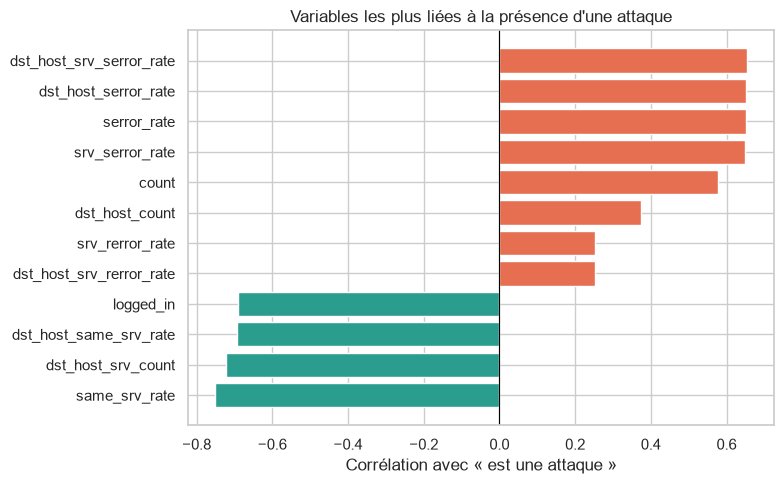

,corrélation
same_srv_rate,-0.752
dst_host_srv_count,-0.723
dst_host_same_srv_rate,-0.694
logged_in,-0.690
dst_host_srv_serror_rate,0.655
dst_host_serror_rate,0.652
serror_rate,0.651
srv_serror_rate,0.648
count,0.576
dst_host_count,0.375


In [14]:
candidates = [c for c in NUMERIC_FEATURES if c not in constant]
correlations = train[candidates].corrwith(train["is_attack"]).sort_values(key=np.abs, ascending=False)
top = correlations.head(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#e76f51" if v > 0 else "#2a9d8f" for v in top]
ax.barh(top.index, top.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Corrélation avec « est une attaque »")
ax.set_title("Variables les plus liées à la présence d'une attaque")
fig.tight_layout()
fig.savefig(FIG_DIR / "top_correlations.png", dpi=150)
plt.show()

correlations.head(12).round(3).to_frame("corrélation")

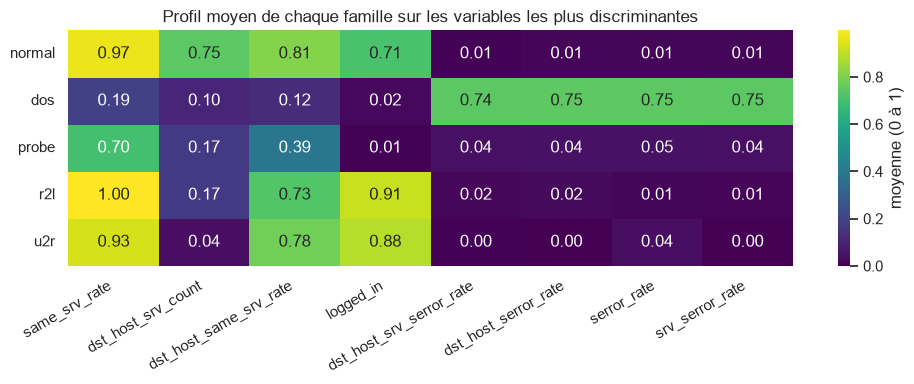

In [15]:
top_features = list(correlations.head(8).index)
scaled = (train[top_features] - train[top_features].min()) / (train[top_features].max() - train[top_features].min())
profiles = scaled.groupby(train["category"], observed=True).mean().reindex(CATEGORIES)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(profiles, annot=True, fmt=".2f", cmap="viridis", cbar_kws={"label": "moyenne (0 à 1)"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Profil moyen de chaque famille sur les variables les plus discriminantes")
ax.tick_params(axis="y", rotation=0)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(FIG_DIR / "family_profiles.png", dpi=150)
plt.show()

## 6. Ce qu'on en retient pour la modélisation

**Le jeu de test ne ressemble pas à l'entraînement, et c'est voulu.** Le trafic normal pèse 53,5 % de l'entraînement mais 43,1 % du test. Les familles R2L et U2R passent de 0,8 % et 0,04 % des connexions à 12,2 % et 0,9 %. Un modèle qui n'a retenu que les proportions de l'entraînement sera mal calibré face au test.

**Près d'un tiers des attaques du test sont d'un type jamais vu.** 17 types d'attaque sur 37 n'existent que dans le test : 3 750 connexions, soit 29,2 % des attaques. C'est le cas de 81,5 % des connexions U2R du test et de 54,3 % des connexions Probe. Le score sur le test mesurera donc la capacité à généraliser, pas seulement à reconnaître ce qu'on a déjà vu.

**Les données sont propres.** Aucune valeur manquante, 16 doublons à l'entraînement et 57 dans le test, négligeables au regard de la taille des fichiers. Une seule colonne constante, `num_outbound_cmds`, qui n'apporte aucune information et sera retirée.

**Les variables catégorielles ne posent pas de valeur inconnue.** Toutes les valeurs de `protocol_type`, `service` et `flag` présentes dans le test existent déjà à l'entraînement. On configurera quand même l'encodage pour ignorer les valeurs inconnues, afin que l'application de démonstration ne plante pas devant une valeur nouvelle.

**Les familles ne se ressemblent pas.** Le DoS se reconnaît à des taux d'erreurs de connexion élevés (autour de 0,75, contre 0,01 pour le trafic normal) et à une faible proportion de connexions vers un même service (0,19 contre 0,97). À l'inverse, R2L et U2R ressemblent au trafic normal sur ces variables : session ouverte (`logged_in` autour de 0,9) et service identique d'une connexion à l'autre. Ces attaques se déroulent dans des sessions d'apparence légitime, ce qui laisse prévoir un rappel nettement plus faible sur ces deux familles.

**Pour la suite :**

- on évaluera avec le rappel et le F1 par famille, pas avec la seule accuracy ;
- les variables numériques seront normalisées, car `src_bytes` et `dst_bytes` sont très asymétriques (les modèles à base d'arbres s'en passent, la régression logistique non) ;
- les corrélations ci-dessus sont dominées par la famille DoS, qui représente à elle seule environ 78 % des attaques de l'entraînement : elles décrivent surtout ce profil, pas les attaques en général.